In [4]:
import json

# ! will NEED PyTorch version 2.5+ --> for scaled_dot_product_attention(enable_gqa=True)
import torch
import training_engine as training_engine 
from inference_engine import advanced_inference, load_model_weights
from transformer_model import Transformer_Model


device = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Device:         {device}")
print(f"PyTorch:        {torch.__version__}")

if torch.cuda.is_available():
    print(f"GPU:            {torch.cuda.get_device_name(0)}")
    print(f"CUDA version:   {torch.version.cuda}")

    print(f"device capability: {torch.cuda.get_device_capability()}")
    print(f"flash_attention_available: {torch.backends.cuda.is_flash_attention_available()}")



Device:         cuda
PyTorch:        2.8.0+cu129
GPU:            NVIDIA GeForce GTX 1660 Ti
CUDA version:   12.9
device capability: (7, 5)
flash_attention_available: False


In [ ]:
from model_config import load_configs


# MoE vs Dense compute-matched
# model_cfg, train_cfg, data_cfg = load_configs("configs/dense_8D.YAML") # params: 9,898,752
model_cfg, train_cfg, data_cfg = load_configs("configs/MoE_4_experts_top_2_expert_hidden_2D.YAML") # params: 9,903,872

# MHA vs GQA
# model_cfg, train_cfg, data_cfg = load_configs("configs/dense_4D_GQA_2_kv_heads_baseline.YAML") # params: 5,966,592
# model_cfg, train_cfg, data_cfg = load_configs("configs/dense_4D_MHA_4_kv_heads.YAML") # params: 6,294,272

print(model_cfg)
print(train_cfg)
print(data_cfg)

ModelConfig(embed_dim=256, vocab_size=2048, max_context_window=512, num_layers=5, tied_embeddings=False, attention=AttentionConfig(num_q_heads=4, num_kv_heads=2, rope_theta=10000.0), ffn=FFNConfig(use_gate=True, mlp_to_embed_expand_factor=2, MoE_num_experts=4, MoE_num_experts_per_tkn=2, MoE_capacity_factor=1.25, MoE_router_aux_loss_coef=0.01, MoE_router_z_loss_coeff=0.0))
TrainConfig(run_name='MoE_4_experts_top_2_expert_hidden_2D', total_steps=1000, batch_size=32, lr=0.001, run_root='../runs', seed=42, weight_decay=0.1, betas=(0.9, 0.95), grad_clip=1.0, warmup_steps=100, min_lr_ratio=0.1, amp='none', eval_every=50, eval_batches=50, log_every=10, checkpoint_every=250, keep_last_n=3)
DataConfig(train_path='../data/tokenized-2048-train-tinyStories-10Mb.bin', val_path='../data/tokenized-2048-valid-tinyStories-1Mb.bin')


In [35]:
torch.manual_seed(train_cfg.seed)
model = Transformer_Model(model_cfg).to(device)

# Optional. Checkpoints/final weights are saved from the unwrapped model, so this is safe.
# model = torch.compile(model, dynamic=True)

print(f"params: {sum(p.numel() for p in model.parameters()):,}")

params: 9,903,872


In [36]:
model = torch.compile(
    model, 
    mode="default",
    dynamic=True, # variable seq_len
    # fullgraph=True,
)          


In [37]:
training_engine.train(model, model_cfg, train_cfg, data_cfg, device)

c:\Users\raman sh\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\_inductor\lowering.py:7095: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(


Step 00000 | val 7.6642 | val ppl 2130.61


c:\Users\raman sh\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\_inductor\lowering.py:7095: UserWarning: 
Online softmax is disabled on the fly since Inductor decides to
split the reduction. Cut an issue to PyTorch if this is an
important use case and you want to speed it up with online
softmax.

  warnings.warn(


Step 00050 | train(avg) 6.5776 | val 6.3462 | val ppl 570.34 | lr 5.10e-04 | gnorm 0.89
Step 00100 | train(avg) 4.8565 | val 4.7717 | val ppl 118.12 | lr 1.00e-03 | gnorm 0.38
Step 00150 | train(avg) 4.1745 | val 4.1630 | val ppl 64.26 | lr 9.93e-04 | gnorm 0.52
Step 00200 | train(avg) 3.7572 | val 3.7678 | val ppl 43.29 | lr 9.73e-04 | gnorm 0.59
Step 00250 | train(avg) 3.4364 | val 3.4961 | val ppl 32.98 | lr 9.40e-04 | gnorm 0.69
Checkpoint saved: ..\runs\MoE_4_experts_top_2_expert_hidden_2D\ckpt_step00000250.pt
Step 00300 | train(avg) 3.2253 | val 3.2974 | val ppl 27.04 | lr 8.95e-04 | gnorm 0.70
Step 00350 | train(avg) 3.0245 | val 3.1559 | val ppl 23.47 | lr 8.39e-04 | gnorm 0.77
Step 00400 | train(avg) 2.8668 | val 3.0505 | val ppl 21.13 | lr 7.75e-04 | gnorm 0.74
Step 00450 | train(avg) 2.7671 | val 2.9557 | val ppl 19.21 | lr 7.04e-04 | gnorm 0.76
Step 00500 | train(avg) 2.6794 | val 2.8948 | val ppl 18.08 | lr 6.28e-04 | gnorm 0.78
Checkpoint saved: ..\runs\MoE_4_experts_top_

WindowsPath('../runs/MoE_4_experts_top_2_expert_hidden_2D')

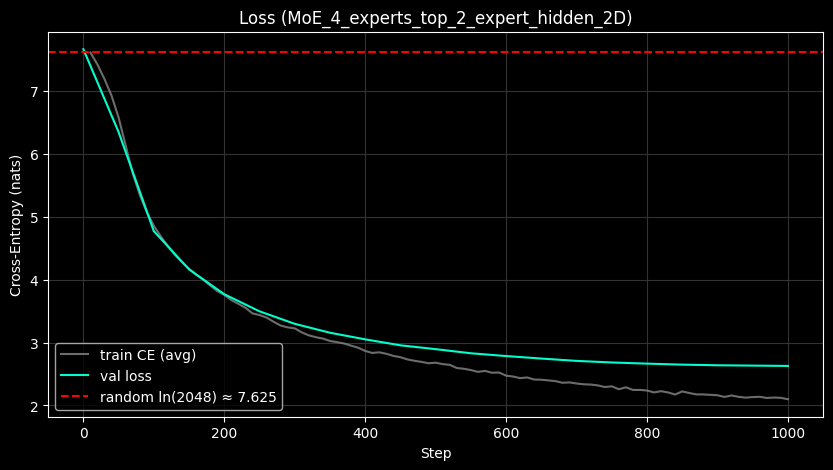

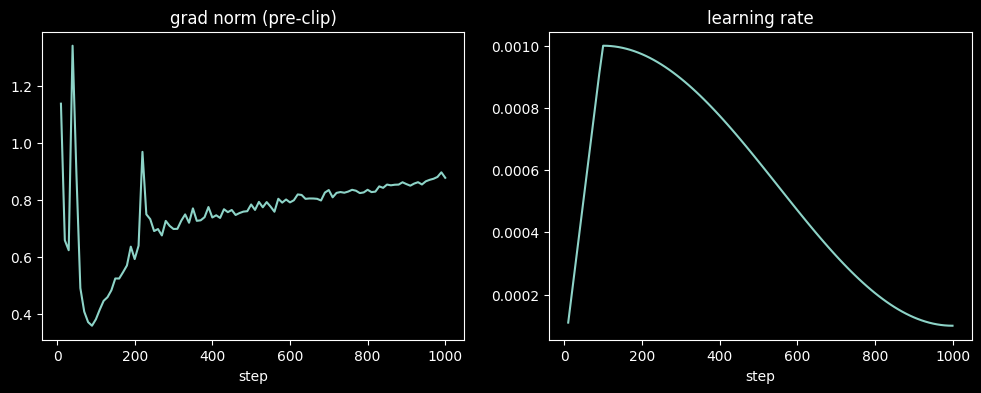

tokens/sec (last log): 47488.02162138936
full val: [{'step': 1000, 'val_loss_full': 2.627978801727295, 'val_ppl_full': 13.845756582141567}]


In [38]:
training_engine.plot_loss_history(train_cfg.run_dir, model_cfg)

import matplotlib.pyplot as plt
rec = training_engine.read_metrics(train_cfg.run_dir)
g = [(r["step"], r["grad_norm"], r["lr"]) for r in rec if "grad_norm" in r]
steps, gn, lr = zip(*g)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(steps, gn);  ax[0].set_title("grad norm (pre-clip)"); ax[0].set_xlabel("step")
ax[1].plot(steps, lr);  ax[1].set_title("learning rate");        ax[1].set_xlabel("step")
plt.show()

print("tokens/sec (last log):", [r["tok_per_s"] for r in rec if "tok_per_s" in r][-1])
print("full val:", [r for r in rec if "val_loss_full" in r])

In [39]:
training_engine.inspect_weight_file(train_cfg.run_dir / "final.pt")


Loaded state_dict from ..\runs\MoE_4_experts_top_2_expert_hidden_2D\final.pt
Number of parameter tensors: 38
Number of parameters: 9,903,872

PARAMETER SUMMARY
embed: shape=(2048, 256), dtype=torch.float32, numel=524,288
unembed: shape=(256, 2048), dtype=torch.float32, numel=524,288
layers.0.norm1.weight: shape=(256,), dtype=torch.float32, numel=256
layers.0.norm2.weight: shape=(256,), dtype=torch.float32, numel=256
layers.0.attention_sub_block.W_qkv: shape=(256, 512), dtype=torch.float32, numel=131,072
layers.0.attention_sub_block.W_o: shape=(256, 256), dtype=torch.float32, numel=65,536
layers.0.ffn_sub_block.router: shape=(256, 4), dtype=torch.float32, numel=1,024
layers.0.ffn_sub_block.W_in: shape=(4, 256, 1024), dtype=torch.float32, numel=1,048,576
layers.0.ffn_sub_block.W_down: shape=(4, 512, 256), dtype=torch.float32, numel=524,288
layers.1.norm1.weight: shape=(256,), dtype=torch.float32, numel=256
layers.1.norm2.weight: shape=(256,), dtype=torch.float32, numel=256
layers.1.atten

In [40]:

with open("2048-tokenizer.json", "r", encoding="utf-8") as f:
    eos_token_id = json.load(f)["special_tokens"]["<|endoftext|>"]

model = load_model_weights(
    Transformer_Model(model_cfg),
    train_cfg.run_dir / "final.pt",
    device,
)

prompt_strs = [
    "write a story about",
    "write like a little boy that was angry",
    "write as a little boy that was happy,",
    "my name is ",
]

results = advanced_inference(
    model=model, configs=model_cfg, prompt_strs=prompt_strs, device=device,
    max_new_tokens=500, max_KV_lanes=2, chunk_size=16, eos_token_id=eos_token_id,
)
for r in results:
    print("---" * 20); print(r.text, f"[{r.finish_reason}]")

[INFO] Loaded weights from ..\runs\MoE_4_experts_top_2_expert_hidden_2D\final.pt (9,903,872 parameters)
------------------------------------------------------------
write a story about a nice man who lives in the world. He says he has real stories. He says he wants to put some water in the story. He says he will send his toe to the river and set to his mom. He hops he will like his toe too. He hops he will not come back. He hops he would like his toes. He hops he will be brave and happy.
 [eos]
------------------------------------------------------------
write like a little boy that was angry. He decided to take a break from his bag and ask them if they can borrow the bag of gold and the bag will make them happy.
Soon, more was done in the next day and it was time to go home. The little boy was proud of his naughty bag and he was very happy. He had found his favorite toy, and his bag was the sealthy and he always wanted to be his friend.
 [eos]
-----------------------------------------